# RBIG Demo

In [1]:
!pip install python-picard
!pip install "git+https://github.com/IPL-UV/rbig.git"

import numpy as np
import warnings
from time import time

# from rbig.model import RBIG
from sklearn.model_selection import train_test_split
from sklearn.utils import check_random_state
import matplotlib.pyplot as plt
plt.style.use('ggplot')
warnings.filterwarnings('ignore') # get rid of annoying warnings

%matplotlib inline
%load_ext autoreload
%autoreload 2

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for python-picard: filename=python_picard-0.8-py3-none-any.whl size=16394 sha256=dbcb6743b7461926933c0b22584ca5a4fc5bc5495e0800e4e43e1fc88a1d98da
  Stored in directory: /root/.cache/pip/wheels/86/7e/fc/6183c6bfdc791d9e7b5a1df84ec4f30055f76bc8414ab2300d
Successfully built python-picard
  Cloning https://github.com/IPL-UV/rbig.git to /tmp/pip-req-build-02gwczbl
  Running command git clone --filter=blob:none --quiet https://github.com/IPL-UV/rbig.git /tmp/pip-req-build-02gwczbl
  Resolved https://github.com/IPL-UV/rbig.git to commit a9124fc07d8e851833802d604fe552b6327ab980
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 15.6 MB/s eta 0:00:00
  Created wheel for py_rbig: filename=py_rbig-0.0.1-py3-none-any.whl size=17468 sha256=7059b1ed8eb90484fb4cf85252d8e758f75843ce1b19bc7e0c9090d53e53cd33
  Stored in dire

#### Toy Data

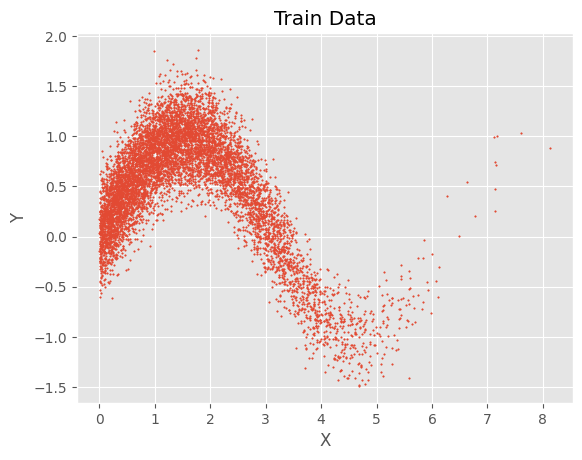

In [2]:
import sklearn

seed = 123
rng = np.random.RandomState(seed=seed)

num_samples = 10000
x = np.abs(2 * rng.randn(1, num_samples))
y = np.sin(x) + 0.25 * rng.randn(1, num_samples)
data = np.vstack((x, y)).T

# Train test
[x_tr, x_ts] =  sklearn.model_selection.train_test_split(data,test_size=0.2)

# plot
fig, ax = plt.subplots()
ax.scatter(x_tr[:, 0], x_tr[:, 1], s=1)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Train Data')
plt.show()

## RBIG Fitting

In [3]:
%%time
from rbig import RBIG

rotation_type = 'pca'
n_layers = 1000
# Initialize RBIG class
rbig_model = RBIG(rotation = rotation_type,
                  max_layers = n_layers,)

# transform data
data_trans = rbig_model.fit_transform(x_tr)

  0%|          | 0/1000 [00:00<?, ?it/s]

CPU times: user 3.22 s, sys: 413 ms, total: 3.64 s
Wall time: 4.25 s


### Estimating Probabilities with RBIG

In [5]:
%%time
prob_input = rbig_model.predict_proba(x_ts)

# Calculamos el nivel de anomalia
# se le aplica una nolinealiedad monotónica a la probabilidad para exagerar el efecto
anomaly = 1-np.log(prob_input+1)**0.1

CPU times: user 29.1 ms, sys: 0 ns, total: 29.1 ms
Wall time: 29 ms


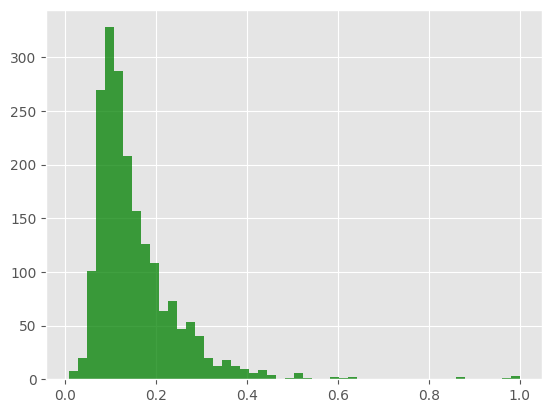

In [6]:
fig, ax = plt.subplots()
ax.hist(anomaly, 50, facecolor='green', alpha=0.75)
plt.show()

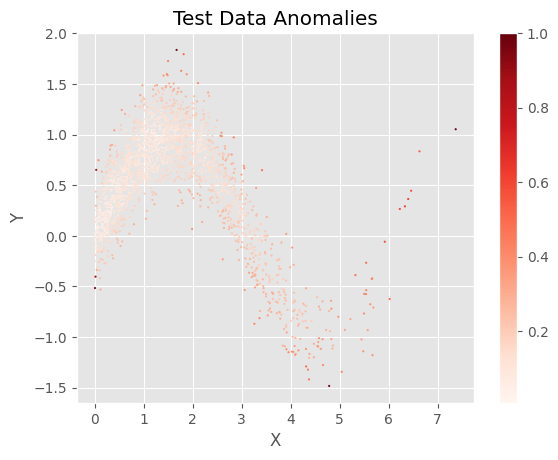

In [7]:
fig, ax = plt.subplots()


h = ax.scatter(x_ts[:, 0], x_ts[:, 1], s=1, c=anomaly, cmap='Reds')

ax.set_xlabel('X')
ax.set_ylabel('Y')
cbar = plt.colorbar(h, )
ax.set_title('Test Data Anomalies')
plt.show()

# Con datos reales de anomalias

In [8]:
# INSTALANDO LA LIBRERIA
!pip install adbench
!pip install --upgrade adbench


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.8/118.8 kB 4.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.0/132.0 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 MB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.1/42.1 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 887.4/887.4 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.1/317.1 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.0/21.0 MB 61.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 46.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 557.1/557.1 MB 3.3 MB/s eta 0:00:00
  Created wheel for pyod: filename=pyod-1.0.0-py3-none-any.whl size=144434 sha256

In [9]:
from adbench.myutils import Utils
utils = Utils() # utility function
# download datasets from the remote github repo
# we recommend jihulab for China mainland user and github otherwise
utils.download_datasets(repo='jihulab')

if there is any question while downloading datasets, we suggest you to download it from the website:
https://github.com/Minqi824/ADBench/tree/main/adbench/datasets
如果您在中国大陆地区，请使用链接：
https://jihulab.com/BraudoCC/ADBench_datasets/


  0%|          | 0/3 [00:00<?, ?it/s]

Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/CV_by_ResNet18/CIFAR10_0.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/CV_by_ResNet18/CIFAR10_1.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/CV_by_ResNet18/CIFAR10_2.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/CV_by_ResNet18/CIFAR10_3.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/CV_by_ResNet18/CIFAR10_4.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/CV_by_ResNet18/CIFAR10_5.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/CV_by_ResNet18/CIFAR10_6.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/CV_by_ResNet18/CIFAR10_7.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/CV_by_ResNet18/CIFAR10_8.npz
Current saving path: /usr/local/lib/p

 33%|███▎      | 1/3 [00:44<01:28, 44.19s/it]

Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/NLP_by_BERT/20news_0.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/NLP_by_BERT/20news_1.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/NLP_by_BERT/20news_2.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/NLP_by_BERT/20news_3.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/NLP_by_BERT/20news_4.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/NLP_by_BERT/20news_5.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/NLP_by_BERT/agnews_0.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/NLP_by_BERT/agnews_1.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/NLP_by_BERT/agnews_2.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/data

 67%|██████▋   | 2/3 [00:57<00:26, 26.20s/it]

Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/Classical/10_cover.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/Classical/11_donors.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/Classical/12_fault.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/Classical/13_fraud.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/Classical/14_glass.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/Classical/15_Hepatitis.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/Classical/16_http.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/Classical/17_InternetAds.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/datasets/Classical/18_Ionosphere.npz
Current saving path: /usr/local/lib/python3.11/dist-packages/adbench/dataset

100%|██████████| 3/3 [01:23<00:00, 27.95s/it]


In [11]:
path = '/usr/local/lib/python3.11/dist-packages/adbench/datasets/Classical/'

import numpy as np
#data = np.load(path + '5_campaign.npz', allow_pickle=True)
data = np.load(path + '6_cardio.npz', allow_pickle=True)
X, y = data['X'], data['y']

In [12]:
import seaborn as sns
import pandas as pd

In [13]:
df = pd.DataFrame(X[:,0:6])
df['y'] = y

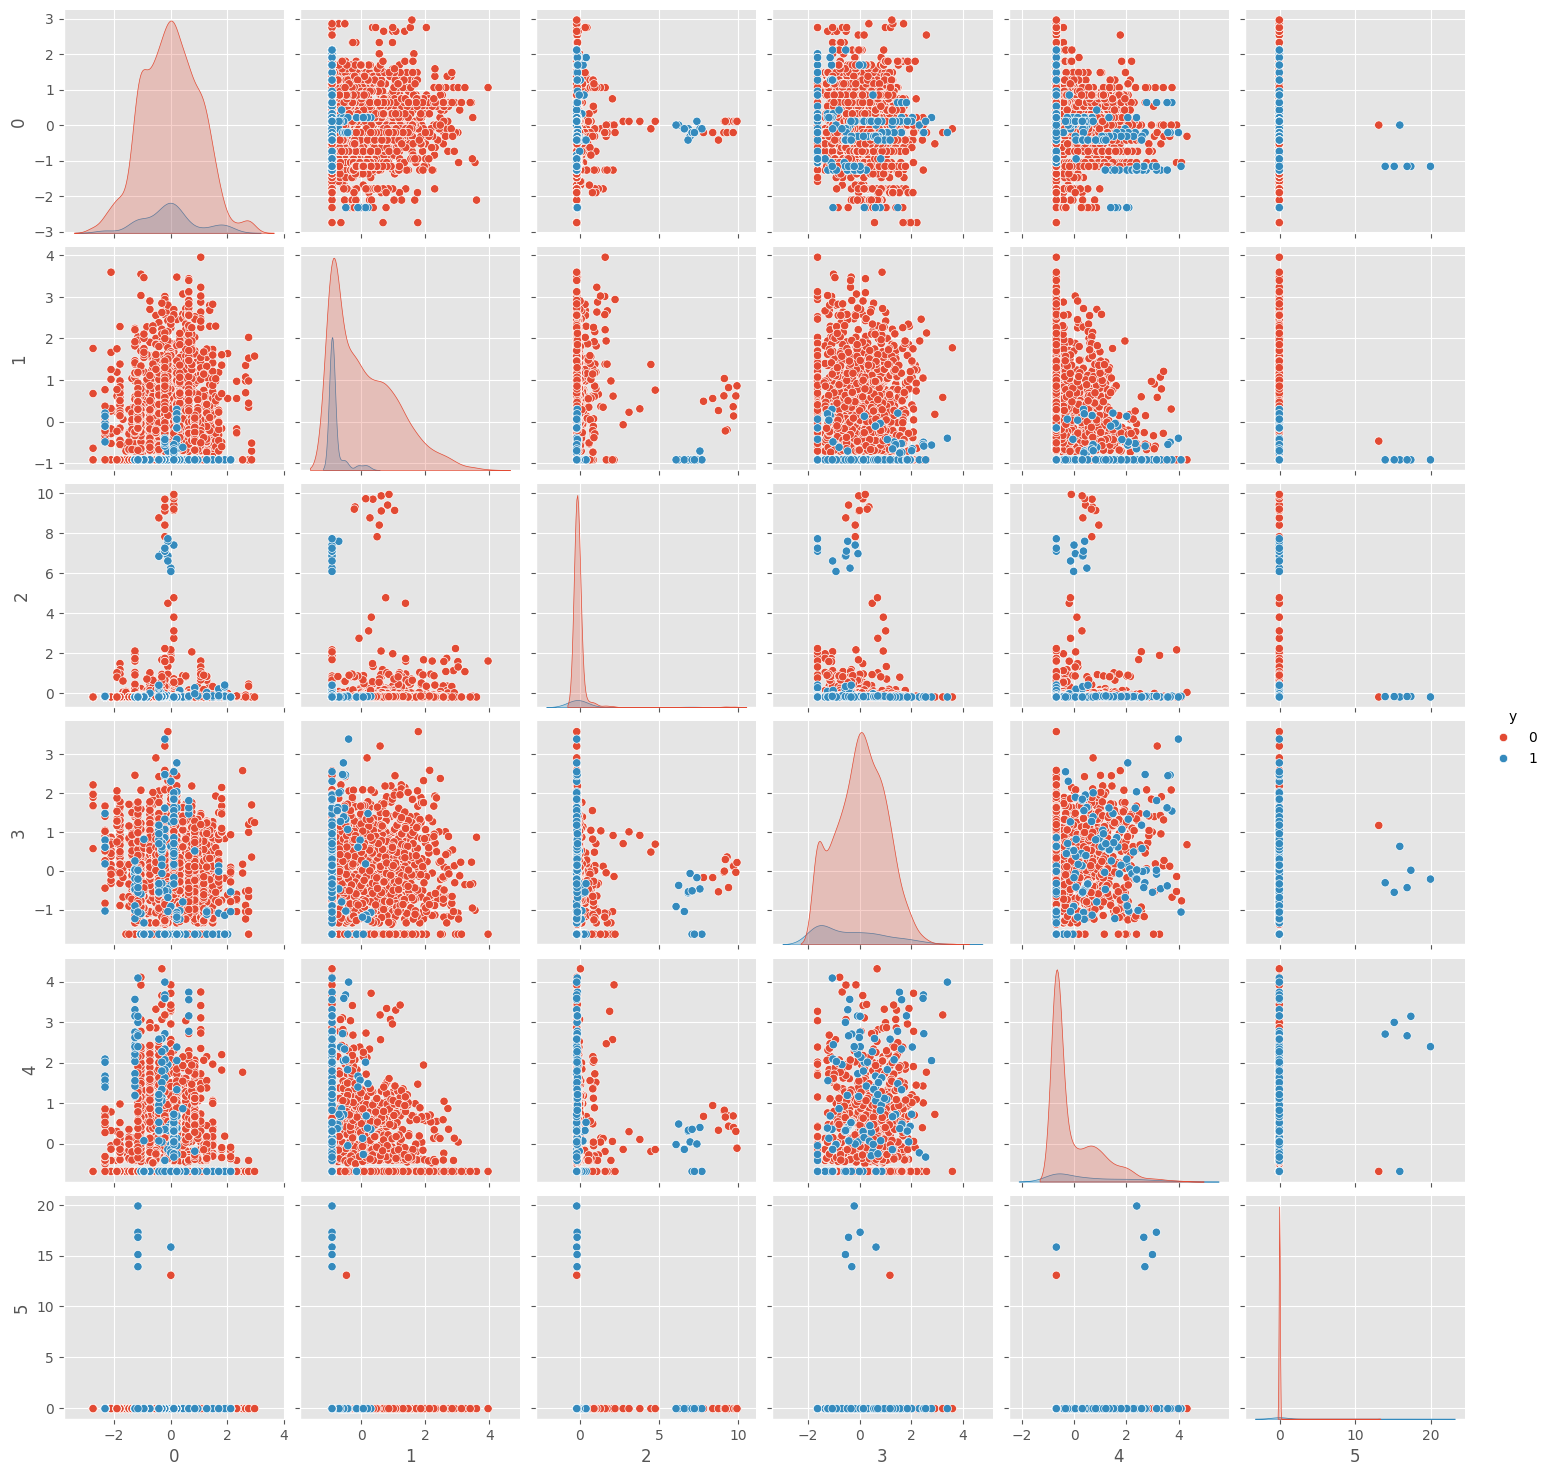

In [14]:
sns.pairplot(df,hue='y')

In [15]:
rotation_type = 'pca'
n_layers = 1000

# Initialize RBIG class
rbig_model = RBIG(rotation = rotation_type,
                  max_layers = n_layers,)

# transform data
data_trans = rbig_model.fit_transform(X)

  0%|          | 0/1000 [00:00<?, ?it/s]

In [16]:
prob_input = rbig_model.predict_proba(X)
anomaly = 1-np.log(prob_input+1)**0.1

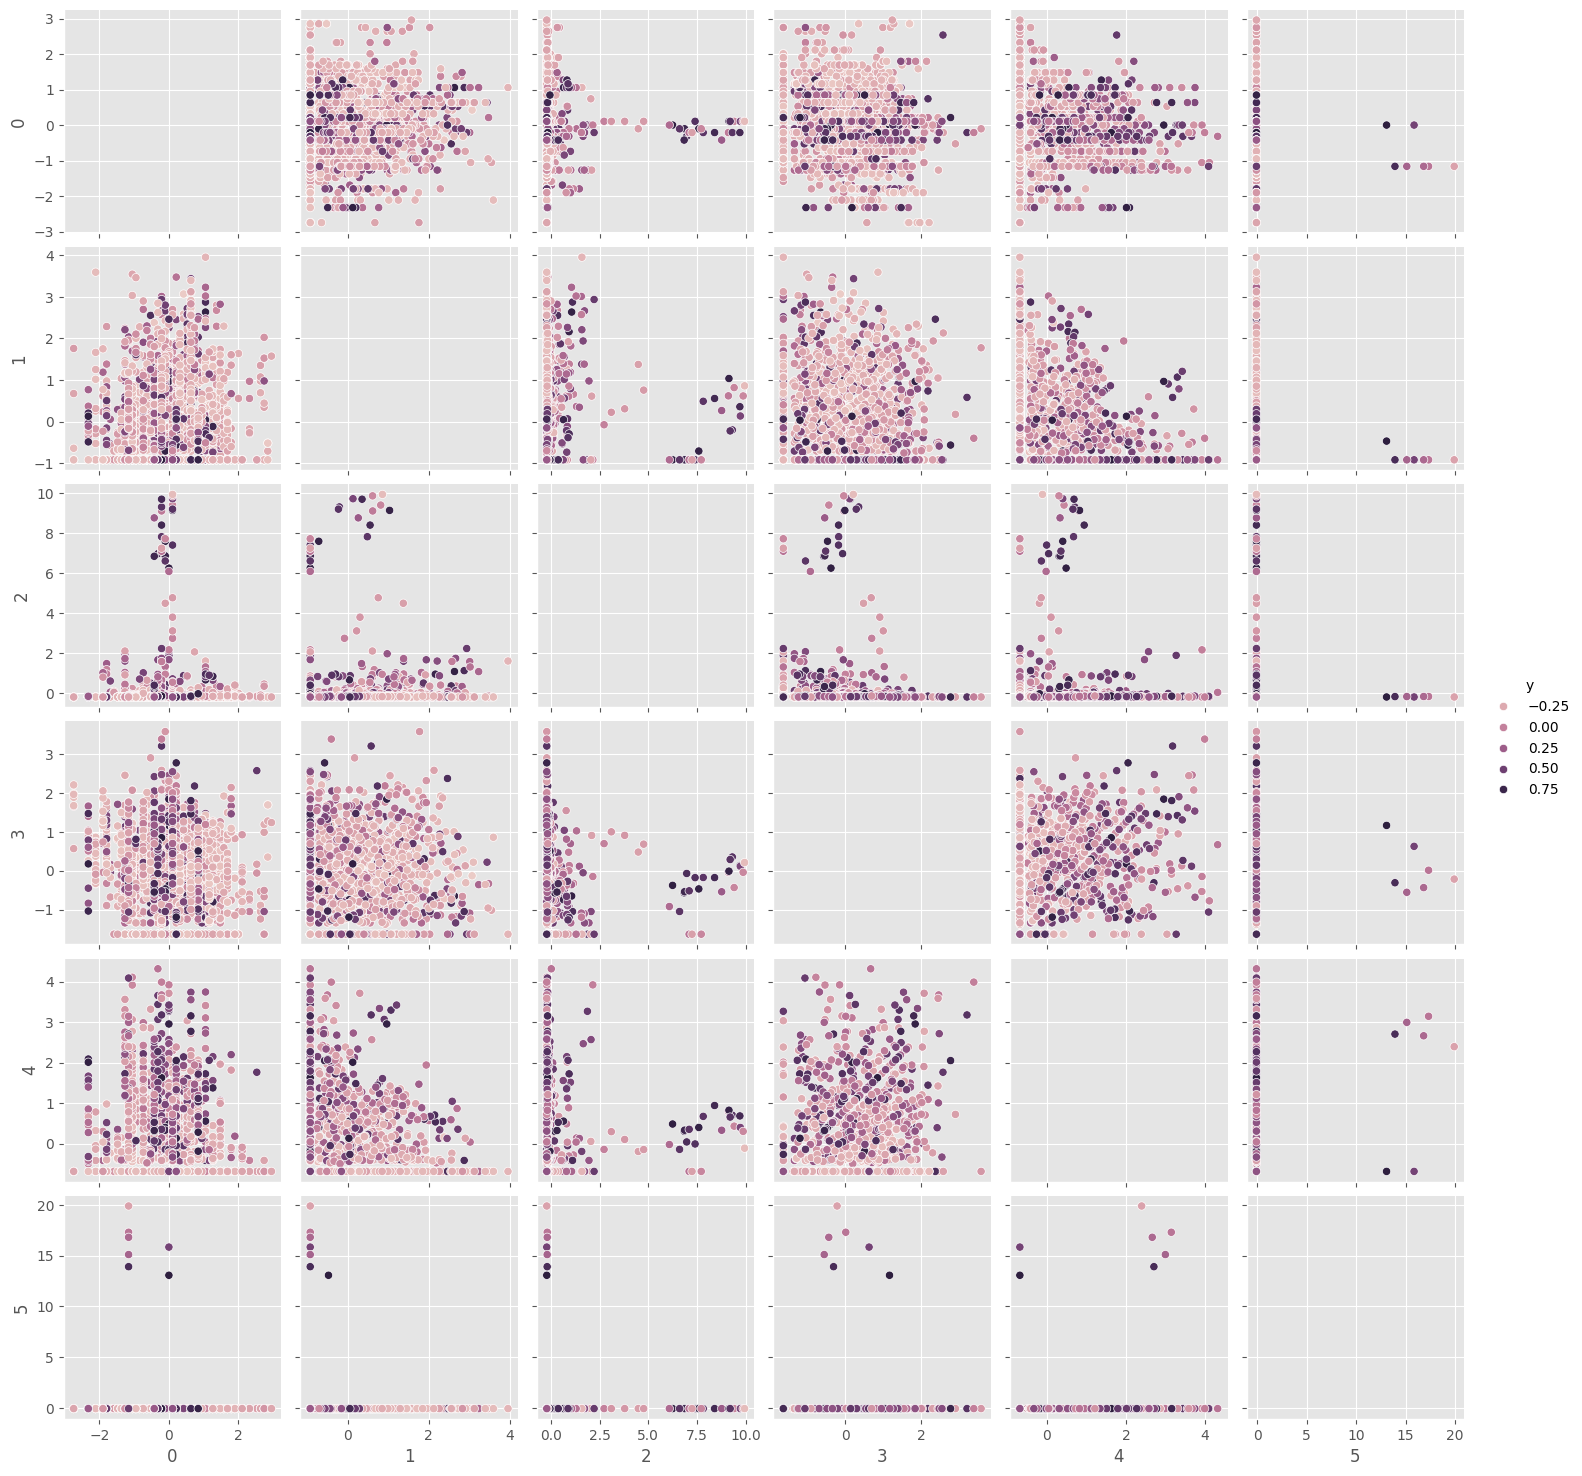

In [17]:
df = pd.DataFrame(X[:,0:6])
yy = anomaly
df['y'] = yy
sns.pairplot(df,hue='y')